# 7. En qué items falla

Cada item se predice con un modelo que no lo vio. El análisis está en `errores.py` y se regenera con `run_analizar_errores.py`.

El reporte sirve para buscar ideas nuevas, pero mirarlo también es una forma de sobreajustar: cualquier idea que salga de acá se valida con folds nuevos antes de adoptarla.

# Análisis de errores del modelo


## 1. Resumen

Sobre 70,000 items de train, cada uno predicho por un modelo que no lo vio, el
accuracy es 0.9470: 3,711 errores. De esos,
2,223 son nuevos predichos como usados y 1,488 usados
predichos como nuevos.


## 2. Cuánto se conoce al vendedor

Según cuántos otros items con etiqueta tenía el vendedor al momento de validar:

| vendedor_conocido   |   items |   % de los items |   tasa_de_error |   errores |   % de los errores |
|:--------------------|--------:|-----------------:|----------------:|----------:|-------------------:|
| ninguno             |   21580 |           30.829 |           0.099 |      2126 |             57.289 |
| 1 o 2               |   11639 |           16.627 |           0.049 |       566 |             15.252 |
| 3 a 5               |    7424 |           10.606 |           0.03  |       224 |              6.036 |
| 6 a 20              |   13368 |           19.097 |           0.034 |       456 |             12.288 |
| más de 20           |   15989 |           22.841 |           0.021 |       339 |              9.135 |

Según cuántos items tiene el vendedor en total (train + test):

| tamano_vendedor   |   items |   % de los items |   tasa_de_error |   errores |   % de los errores |
|:------------------|--------:|-----------------:|----------------:|----------:|-------------------:|
| 1 (único item)    |   17503 |           25.004 |           0.104 |      1814 |             48.882 |
| 2                 |    6524 |            9.32  |           0.069 |       450 |             12.126 |
| 3 a 5             |    9087 |           12.981 |           0.043 |       393 |             10.59  |
| 6 a 20            |   14509 |           20.727 |           0.034 |       495 |             13.339 |
| más de 20         |   22377 |           31.967 |           0.025 |       559 |             15.063 |



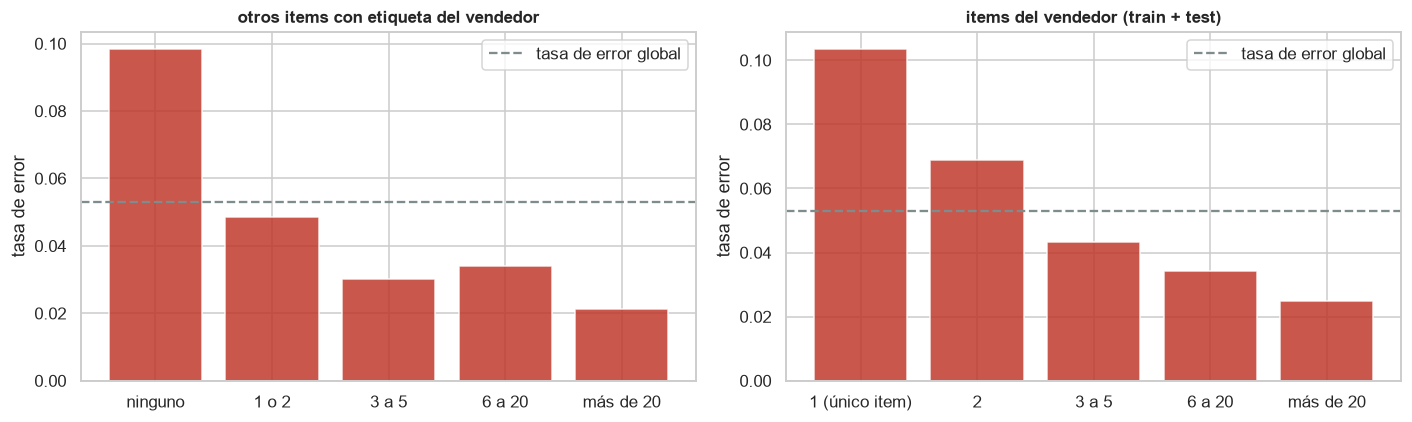



**El modelo falla sobre todo donde no conoce al vendedor.** Los items cuyo vendedor
no tiene ningún otro item con etiqueta son el 31% de los datos
y concentran el 57% de los errores, con una tasa de error de
9.9%. La mayoría son vendedores de un único item
(17,503 items, 10.4% de error): para ellos no
hay otras publicaciones en las que apoyarse, ni en train ni en test, y solo queda lo
que dice la propia publicación.


## 3. Confianza del modelo

| tramo_de_confianza   |   items |   % de los items |   tasa_de_error |   errores |   % de los errores |
|:---------------------|--------:|-----------------:|----------------:|----------:|-------------------:|
| (0.499, 0.6]         |     658 |            0.94  |           0.508 |       334 |              9     |
| (0.6, 0.7]           |     738 |            1.054 |           0.425 |       314 |              8.461 |
| (0.7, 0.8]           |     955 |            1.364 |           0.396 |       378 |             10.186 |
| (0.8, 0.9]           |    1506 |            2.151 |           0.311 |       469 |             12.638 |
| (0.9, 1.0]           |   66143 |           94.49  |           0.034 |      2216 |             59.714 |

El modelo se cree más seguro de lo que es: por su confianza esperaría
1.8% de error, y el real es 5.3%.
Cuando está muy seguro (más de 90%) falla el 3.4%.
Como casi todos los items caen en ese tramo, esos fallos son
2,216, el 60% de todos los
errores.


## 4. Errores con el modelo muy seguro

| título                                                  | etiqueta   |   proba usado |   stock inicial | tipo         | garantía                       |
|:--------------------------------------------------------|:-----------|--------------:|----------------:|:-------------|:-------------------------------|
| Bisel Marco Frontal De Carcasa Lg G Pro E980 E985 F240  | used       |             0 |             900 | bronze       | si                             |
| Pedal De Afinador Behringer Tu300 Cromatico Guitarra -  | used       |             0 |               1 | bronze       | Sí                             |
| Hidrolavadora Hyew65-1600 Outlet Oferta Hyundai Rpm Cab | used       |             0 |              10 | silver       | 6 meses                        |
| Cilindros Fichet (cambio De Combinacion)#               | used       |             0 |               3 | bronze       | De por vida                    |
| 100 Soldaditos De Guerra Plasticos Souvenirs Juegos Jug | used       |             0 |             499 | bronze       |                                |
| Toner Hp Q6002a Original Vacío 124a Amar. 1er Uso Excel | used       |             0 |              17 | bronze       |                                |
| Libro Digital - El Creador - Eduardo Zannini - Nuevo!   | used       |             0 |              10 | silver       | Sin garantía                   |
| Mercedes Benz Clase C 2007                              | new        |             1 |               1 | gold_premium |                                |
| Cruz Lisa De Acero Con Cadena  - Ben Junot - Varios Tam | used       |             0 |              20 | bronze       |                                |
| Preparacion Para El Choque Pachter, Henry  (art 5967    | new        |             1 |               1 | bronze       | Sí                             |
| Recarga Toner Xerox Xc 3220 - 3210 -cod 106r01487       | used       |             0 |               5 | bronze       |                                |
| En Busca De Dios - Edith Stein ( Libro Digital )        | used       |             0 |               7 | bronze       |                                |
| Bobina De Encendido Cortadora Cesped Gamma De 3,5hp A 6 | used       |             0 |               3 | bronze       | 3 meses por defectos de fabric |
| Cachorros Shar Pei  ºº Criadero Aldea Of Peis           | used       |             0 |              24 | silver       | Sin garantía                   |
| Campera Adidas Running Clima Anthem Original            | used       |             0 |               1 | bronze       |                                |
| Centros De Mesa Rusticos Casamientos, 15 Años, Comunion | used       |             0 |              10 | silver       |                                |
| Matafuegos Polvo 2,5 Kg Paternal Sello Iram Canje Inmed | used       |             0 |             999 | gold_special | Con garantía de 1 año para la  |
| Volver A Empezar   Paola C. Alvarez            Libro Di | used       |             0 |              10 | bronze       | 100% DE CALIFICACIONES POSITIV |
| La Metamorfosis Y Otros Relatos / Kafka (la Nación, 200 | new        |             1 |               1 | bronze       |                                |
| Recarga Brother Cartuchos Tinta Brother Neg/cian/mag/am | used       |             0 |              10 | bronze       | Brother MFC 230C 240C 350C 440 |

Muchos de estos casos parecen etiquetas dudosas más que errores del modelo:
repuestos y consumibles con cientos de unidades de stock marcados como usados,
"libros digitales" con stock múltiple marcados como usados, o autos de varios años
marcados como nuevos. La condición la declara el vendedor y no siempre la carga
bien. Esto pone un techo al accuracy que ningún modelo puede superar.


## 5. Rol del item dentro de su vendedor

| rol_en_el_vendedor               |   items |   % de los items |   tasa_de_error |   errores |   % de los errores |
|:---------------------------------|--------:|-----------------:|----------------:|----------:|-------------------:|
| mayoría de un vendedor casi puro |   30958 |           44.226 |           0.003 |        79 |              2.129 |
| minoría de un vendedor casi puro |     701 |            1.001 |           0.582 |       408 |             10.994 |
| vendedor con pocos items         |   34234 |           48.906 |           0.079 |      2705 |             72.891 |
| vendedor mixto                   |    4107 |            5.867 |           0.126 |       519 |             13.985 |

Un vendedor es "casi puro" si tiene 5 o más items con etiqueta y al
menos 80% son de la misma clase. Los items que son la excepción de su
vendedor (el único usado de un comercio, o el único nuevo de un particular) fallan
el 58% de las veces: la señal más fuerte del modelo apunta
justo en la dirección contraria.


## 6. Tipo de publicación y stock

| listing_type_id   |   items |   % de los items |   tasa_de_error |   errores |   % de los errores |
|:------------------|--------:|-----------------:|----------------:|----------:|-------------------:|
| bronze            |   44143 |           63.061 |           0.058 |      2569 |             69.227 |
| free              |   15047 |           21.496 |           0.056 |       844 |             22.743 |
| gold              |    1713 |            2.447 |           0.016 |        28 |              0.755 |
| gold_premium      |     587 |            0.839 |           0.017 |        10 |              0.269 |
| gold_pro          |      13 |            0.019 |           0     |         0 |              0     |
| gold_special      |    2134 |            3.049 |           0.001 |         2 |              0.054 |
| silver            |    6363 |            9.09  |           0.041 |       258 |              6.952 |

| stock_inicial   |   items |   % de los items |   tasa_de_error |   errores |   % de los errores |
|:----------------|--------:|-----------------:|----------------:|----------:|-------------------:|
| 1 unidad        |   49156 |           70.223 |           0.069 |      3382 |             91.134 |
| más de 1        |   20844 |           29.777 |           0.016 |       329 |              8.866 |

Con más de una unidad casi no hay errores. El problema está en las publicaciones
`bronze` de una sola unidad, que pueden ser tanto de un comercio como de un
particular.


## 7. Categorías con más errores

| category_id   |   items |   errores |   tasa_de_error |   tasa_de_usados | ejemplo                                       |
|:--------------|--------:|----------:|----------------:|-----------------:|:----------------------------------------------|
| MLA1227       |    3180 |        82 |           0.026 |            0.508 | Camino De La Perfeccion El - Dyer Wayne -nuev |
| MLA3530       |     542 |        64 |           0.118 |            0.402 | Repuesto Pluma Parker Legítima Dorada         |
| MLA2044       |    1359 |        62 |           0.046 |            0.746 | El Huesped. Margarita Aguirre.                |
| MLA41287      |     629 |        33 |           0.052 |            0.868 | Aventuras De Robinson Crusoe - Daniel Defoe - |
| MLA15171      |     410 |        32 |           0.078 |            0.624 | Alcatrazz Cd  Dangerous Games                 |
| MLA4335       |     204 |        22 |           0.108 |            0.319 | Adorno, Tucán                                 |
| MLA1635       |     161 |        21 |           0.13  |            0.342 | Cuadros Modernos Abstractos Tripticos         |
| MLA15204      |     319 |        20 |           0.063 |            0.47  | Adam Tully Guitar                             |
| MLA15226      |     184 |        19 |           0.103 |            0.576 | Jimi Hendrix - West Coast Seattle Boy (cd + D |
| MLA370638     |     129 |        18 |           0.14  |            0.636 | Sandalias De Lady Comfort                     |
| MLA1458       |     118 |        17 |           0.144 |            0.517 | Pantalones Dama                               |
| MLA1383       |     315 |        16 |           0.051 |            0.924 | Tapas 382                                     |


In [1]:
import sys
import warnings

sys.path.insert(0, "..")  # Los módulos están en la raíz del proyecto
warnings.filterwarnings("ignore")
%matplotlib inline

import config
from eda.reporte import mostrar_markdown

carpeta = config.OUTPUTS / "errores"
mostrar_markdown((carpeta / "REPORTE_ERRORES.md").read_text(encoding="utf8"), carpeta)